# Figures
This notebook uses the in vitro data to create publication-ready figures.
Additionally, the in silico data from all previous notebooks is used again to create figures.
The goal is to have figures that allow the reader to easily compare both approaches and see similarities and differences.

Overall, the variables often will have the following suffixes:
- _V for in vitro data
- _S for in silico data

# Imports & Functions

In [1]:
# import own functions
from functions import *

# plots
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
def custom_format(x):
    if round(x,2) == 0:
        return "0"          # no decimals for 0
    else:
        return f"{x:.2f}"   # 2 decimals otherwise

# Load CSV Files


In [3]:
path_to_figures = "../Figures/" # where to save Figures

In [4]:
order = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu", "C7"]
# order_c6 = ["C7", "C6–Sma", "C6–Bpi", "C6–Cpu", "C6–Elu", "C6–Cin", "C6–Hro", "C6–Ppu"]
order_c6 = ["C6–Sma", "C6–Bpi", "C6–Cpu", "C6–Elu", "C6–Cin", "C6–Hro", "C6–Ppu", "C7"]

In [5]:
sns.reset_defaults()

In [6]:
ecoplate_categories = pd.read_csv("../Datasets/in_vitro_data/Ecoplate_Chemical-categories.csv", sep=";")
ecoplate_substrate_names = pd.read_csv("../Datasets/Ecoplate_Substrate_Names.csv", sep=";")

## In vitro data

In [7]:
path_to_files = "../Datasets/in_vitro_data" # in vitro data

depletion_all = pd.read_csv(f"{path_to_files}/Depletion.csv", delimiter=";", decimal=",", index_col="Feature name")
depletion_primary_V = pd.read_csv(f"{path_to_files}/Depletion-primary.csv", delimiter=";", decimal=",", index_col="Metabolite")
enrichment_all = pd.read_csv(f"{path_to_files}/Enrichment.csv", delimiter=";", decimal=",", index_col="Feature name")
ecoplate_ind_V = pd.read_csv(f"{path_to_files}/Ecoplate_Ind-C7.csv", delimiter=";", decimal=",", index_col="Substrate")
ecoplate_c6_V = pd.read_csv(f"{path_to_files}/Ecoplate_C7-C6.csv", delimiter=";", decimal=",", index_col="Substrate")

carbon_util_V = pd.read_csv(f"{path_to_files}/Carbon-Util.csv", delimiter=";", decimal=",", index_col="Carbon Source")
carbon_util_alanine_V = pd.read_csv(f"{path_to_files}/Carbon-Util_Growth-alanine.csv", delimiter=";", decimal=",")

cross_feeding_V = pd.read_csv(f"{path_to_files}/Cross-Feeding.csv", delimiter=";", decimal=",")
cross_feeding_bpi_V = pd.read_csv(f"{path_to_files}/Cross-Feeding_Growth-Bpi.csv", delimiter=";", decimal=",")

vitamin_V = pd.read_csv(f"{path_to_files}/Vitamin.csv", delimiter=";", decimal=",")
vitamin_bpi_elu_V = pd.read_csv(f"{path_to_files}/Vitamin_Growth_Bpi-Elu.csv", delimiter=";", decimal=",")

vitamin_V1_bpi_V = pd.read_csv(f"{path_to_files}/Vitamin_V1-Bpi.csv", delimiter=";", decimal=",")
vitamin_V7_bpi_V = pd.read_csv(f"{path_to_files}/Vitamin_V7-Bpi.csv", delimiter=";", decimal=",")
vitamin_growth_bpi_V = pd.read_csv(f"{path_to_files}/Vitamin_Growth-Bpi.csv", delimiter=";", decimal=",")

vitamin_V1_cpu_V = pd.read_csv(f"{path_to_files}/Vitamin_V1-Cpu.csv", delimiter=";", decimal=",")
vitamin_V7_cpu_V = pd.read_csv(f"{path_to_files}/Vitamin_V7-Cpu.csv", delimiter=";", decimal=",")

heterocyclic = pd.read_csv("../Datasets/in_vitro_data/Organoheterocyclic_Compounds_LCMS.csv", sep=";", index_col="Strain")

## In silico data

In [8]:
path_to_files = "../Datasets/in_silico_data" # in silico data

depletion_primary_S = pd.read_csv(f"{path_to_files}/4-3_Uptakes_Krumbach_mean.csv", delimiter=",", decimal=".", index_col="Metabolite")
ecoplate_ind_S = pd.read_csv(f"{path_to_files}/4-5_Ecoplate.csv", delimiter=",", decimal=".", index_col="Substrate")
carbon_util_S = pd.read_csv(f"{path_to_files}/4-6_Growth_Carbon_Sources.csv", delimiter=",", decimal=".", index_col="Substrate")
cross_feeding_S = pd.read_csv(f"{path_to_files}/4-7_Cross-Feeding.csv", delimiter=",", decimal=".", index_col="Medium")
ecoplate_c6_S = pd.read_csv(f"{path_to_files}/A-10_Ecoplate_C6.csv", delimiter=",", decimal=".", index_col="Substrate")

vitamin_S = pd.read_csv(f"{path_to_files}/4-11_Vitamins.csv", delimiter=",", decimal=".", index_col="model_id")
vitamin_V1_V7_bpi_S = pd.read_csv(f"{path_to_files}/Vitamins_V1-V7_Bpi.csv", delimiter=";", decimal=".", index_col="Vitamins")
vitamin_V1_V7_cpu_S = pd.read_csv(f"{path_to_files}/Vitamins_V1-V7_Cpu.csv", delimiter=";", decimal=".", index_col="Vitamins")

# Depletion and Enrichment Heatmaps

## In vitro Depletion (all)

In [9]:
depletion_all_mean_V = (
    depletion_all.groupby(depletion_all.columns.str.split('_r').str[0], axis=1)
    .mean()
)

In [10]:
depletion_all_mean_V = depletion_all_mean_V[order]

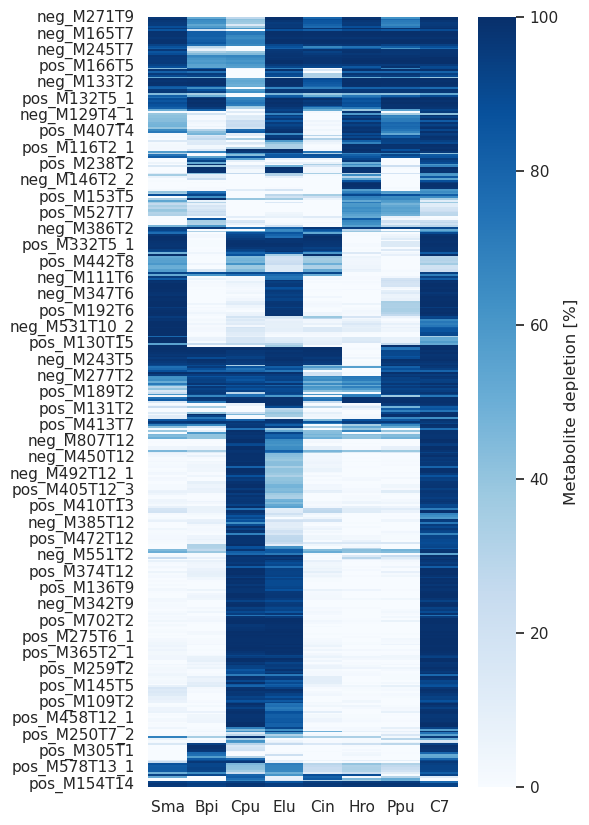

In [11]:
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(5,10)})

ax = sns.heatmap(
    depletion_all_mean_V, # these are relative values
    cmap="Blues",
    cbar_kws={"label": "Metabolite depletion [%]"}
)

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}K_1a_Depletion-all.svg", format="svg", bbox_inches="tight")
plt.show()

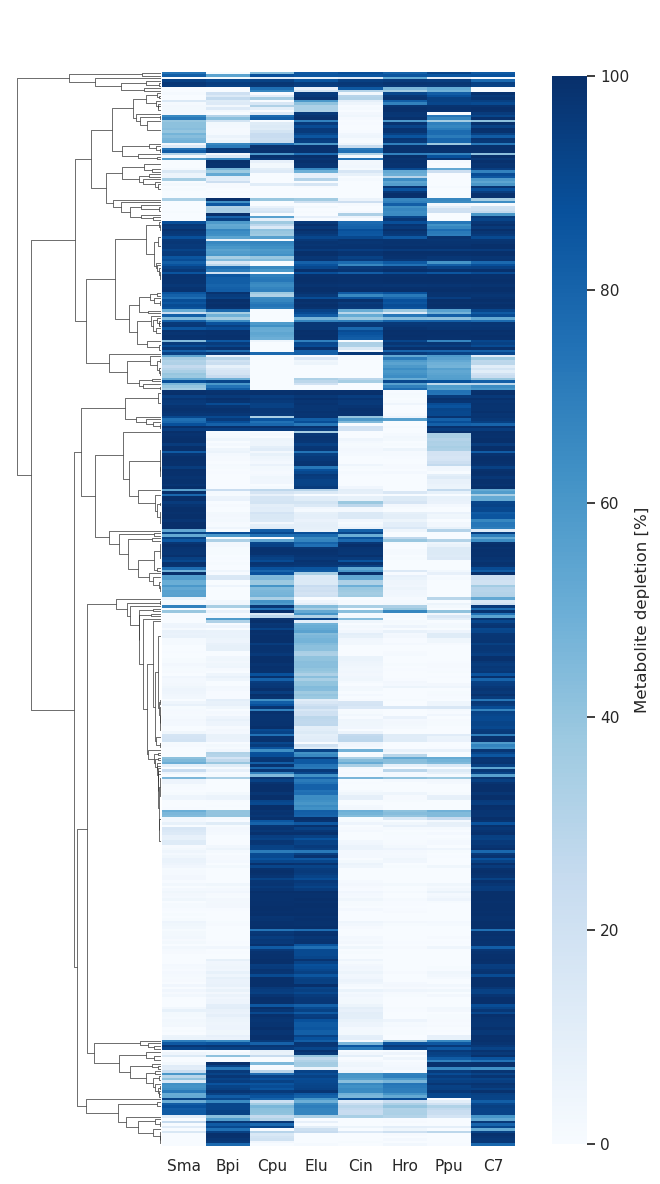

In [12]:
# with clustering
sns.set_style("darkgrid")

g = sns.clustermap(
    depletion_all_mean_V,
    cmap="Blues",
    figsize=(7, 12),
    cbar_kws={"label": "Metabolite depletion [%]"},
    metric="correlation", # Pearson was used in vitro
    method="average",
    standard_scale=None,
    row_cluster=True,
    col_cluster=False,
    dendrogram_ratio=(0.3, 0.05)  # (row, column)
)

g.ax_heatmap.set_ylabel("")
g.ax_heatmap.set_yticklabels([])

# remove y axis tick marks but keep labels
g.ax_heatmap.tick_params(axis="y", length=0)

# Move colour bar to the right and make it full height
g.cax.set_position([0.8, 0.04, 0.05, 0.89]) # [x, y, width, height]

#plt.savefig(f"{path_to_figures}K_1a_Depletion-all.svg", format="svg", bbox_inches="tight")
plt.show()

## In vitro Enrichment (all)

In [13]:
enrichment_all_mean_V = (
    enrichment_all.groupby(enrichment_all.columns.str.split('_r').str[0], axis=1)
    .mean()
)

enrichment_all_mean_V = enrichment_all_mean_V[order]

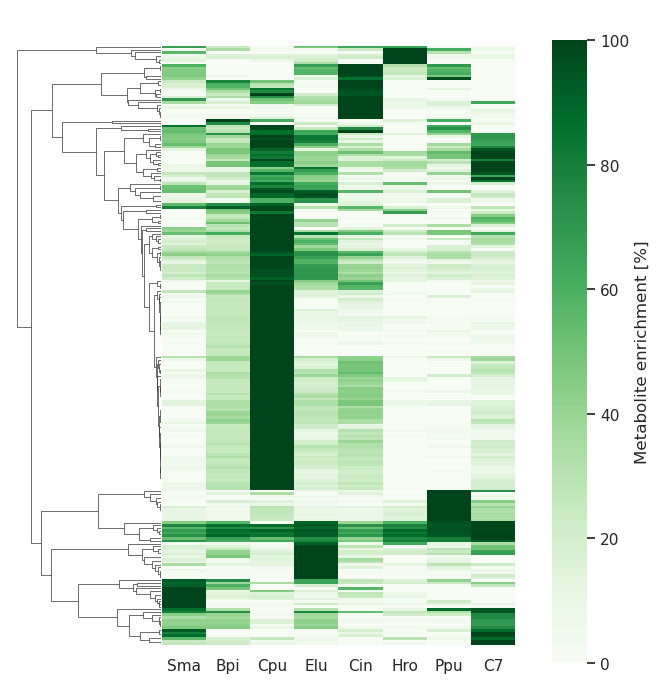

In [14]:
# with clustering
sns.set_style("darkgrid")

g = sns.clustermap(
    enrichment_all_mean_V,
    cmap="Greens",
    figsize=(7, 7),
    cbar_kws={"label": "Metabolite enrichment [%]"},
    metric="correlation", # Pearson was used in vitro
    method="average",
    standard_scale=None,
    row_cluster=True,
    col_cluster=False,
    dendrogram_ratio=(0.3, 0.05)  # (row, column)
)

g.ax_heatmap.set_ylabel("")
g.ax_heatmap.set_yticklabels([])

# remove y axis tick marks but keep labels
g.ax_heatmap.tick_params(axis="y", length=0)

# Move colour bar to the right and make it full height
g.cax.set_position([0.8, 0.04, 0.05, 0.89]) # [x, y, width, height]

#plt.savefig(f"{path_to_figures}K_1d_Enrichment-all.svg", format="svg", bbox_inches="tight")
plt.show()

## In vitro & in silico Depletion (primary)

In [15]:
depletion_primary_mean_V = (
    depletion_primary_V.groupby(depletion_primary_V.columns.str.split('_r').str[0], axis=1)
    .mean()
)

In [16]:
depletion_primary_mean_V = depletion_primary_mean_V[order]

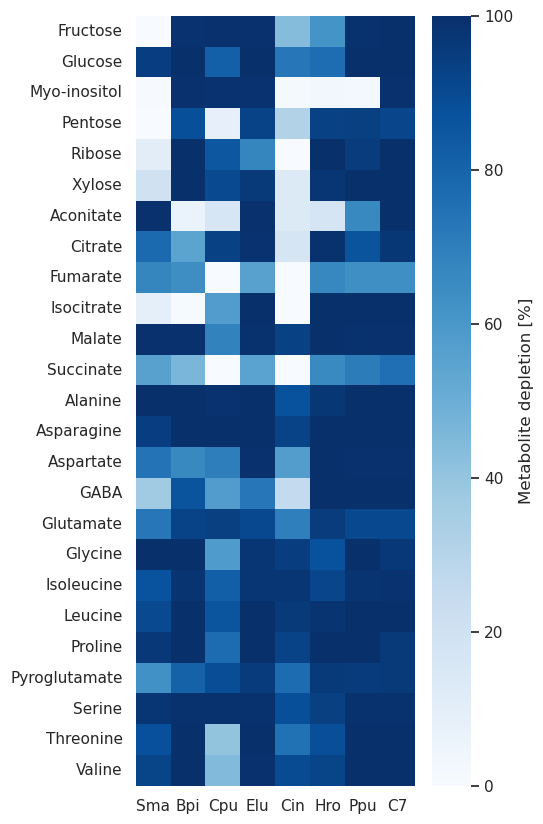

In [17]:
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(4.5,10)})

ax = sns.heatmap(
    depletion_primary_mean_V, # these are relative values
    cmap="Blues",
    cbar_kws={"label": "Metabolite depletion [%]"}
)

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}K_S1a_Depletion-primary-full.svg", format="svg", bbox_inches="tight")
plt.show()

In [18]:
depletion_primary_S = depletion_primary_S.reindex(
    depletion_primary_mean_V.index
) # get same order of rows as in _V df
# !!! This is also drops all rows from _S that are not in _V
# which is nice because my _S df contained M9 medium stuff

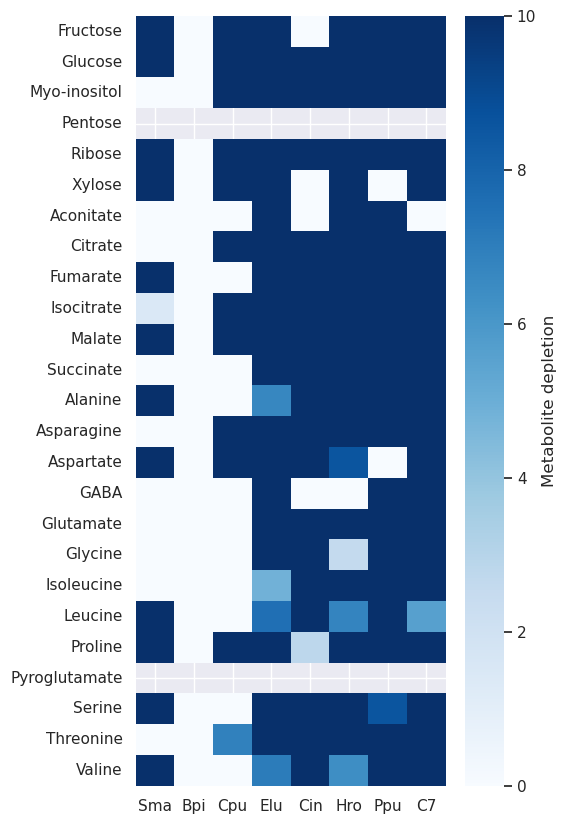

In [19]:
### ABSOLUTE VALUES ####
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(5,10)})

ax = sns.heatmap(
    depletion_primary_S, # these are absolute values
    cmap="Blues",
    cbar_kws={"label": "Metabolite depletion"}
)

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}L_S1a_Depletion-primary-full.svg", format="svg", bbox_inches="tight")
plt.show()

In [20]:
depletion_primary_relative_S = depletion_primary_S * 10
# getting percentages: so 10 is upper bound (so max depletion)
# e.g. 1.5 out of 10 (=100%)
# 100% / 10 * actual value = 10 * actual value

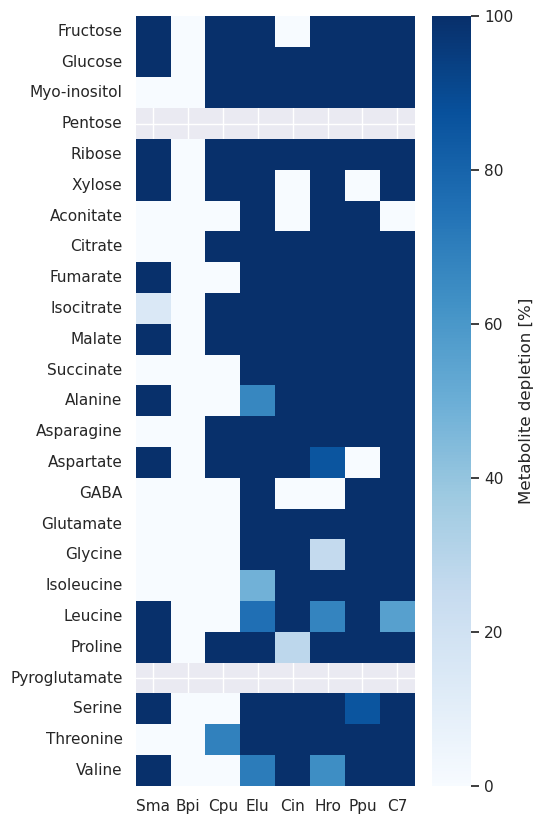

In [21]:
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(4.5,10)})

ax = sns.heatmap(
    depletion_primary_relative_S,
    cmap="Blues",
    cbar_kws={"label": "Metabolite depletion [%]"}
)

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}L_S1a_Depletion-primary_relative-full.svg", format="svg", bbox_inches="tight")
plt.show()

### trimmed

In [22]:
rows_to_drop = ["Pentose", "Pyroglutamate"]

depletion_primary_relative_S.drop(index=rows_to_drop, inplace=True)
depletion_primary_mean_V.drop(index=rows_to_drop, inplace=True)

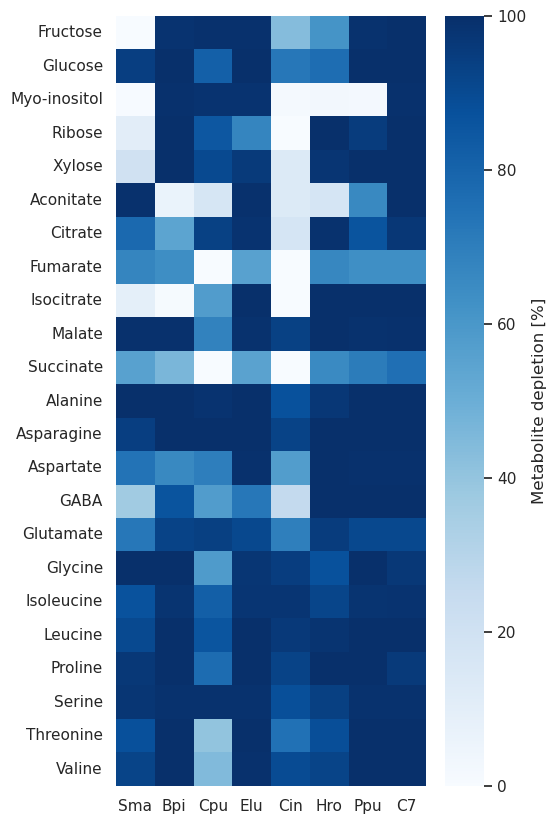

In [23]:
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(5,10)})

ax = sns.heatmap(
    depletion_primary_mean_V, # these are relative values
    cmap="Blues",
    cbar_kws={"label": "Metabolite depletion [%]"}
)

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}K_S1a_Depletion-primary.svg", format="svg", bbox_inches="tight")
plt.show()

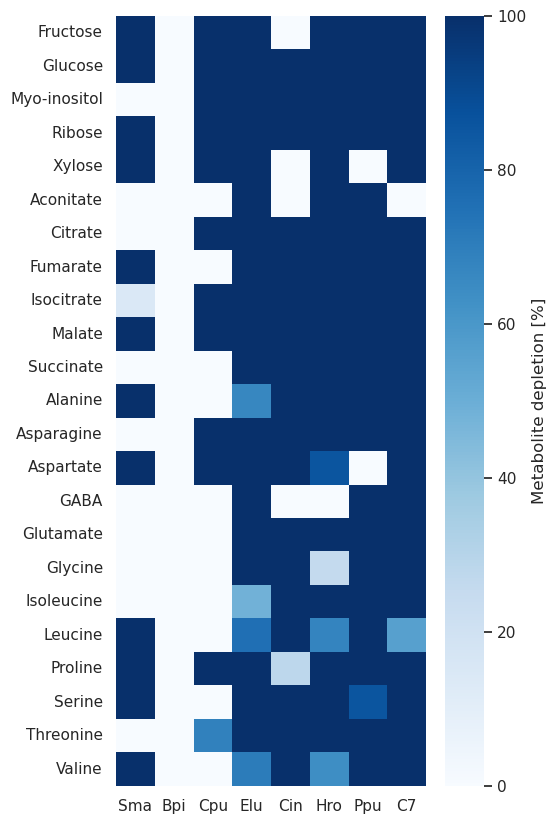

In [24]:
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(5,10)})

ax = sns.heatmap(
    depletion_primary_relative_S,
    cmap="Blues",
    cbar_kws={"label": "Metabolite depletion [%]"}
)

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}L_S1a_Depletion-primary_relative.svg", format="svg", bbox_inches="tight")
plt.show()

# Enrichment (aka Secretion) in silico on Krumbach medium

In [25]:
secret_df = pd.read_csv("../Datasets/in_silico_data/Secretion_Krumbach.csv", index_col=0)

In [ ]:
# TODO: wo kommt diese Datei her

In [26]:
secret_mapping = {
    "CO2 CO2": "Carbon dioxide",
    "H2O H2O": "Water",
    " 3 hydroxydecanoic acid": "3-Hydroxydecanoic acid",
    " 3 Hydroxyhexadecanoic acid": "3-Hydroxyhexadecanoic acid",
    "D-Alanine": "Alanine",
    "Fe2+ mitochondria": "Iron"
}

In [27]:
secret_df = secret_df.rename(
    index=lambda idx: secret_mapping.get(idx, idx)
)

In [28]:
secret_df.sort_index(axis=0, inplace=True)

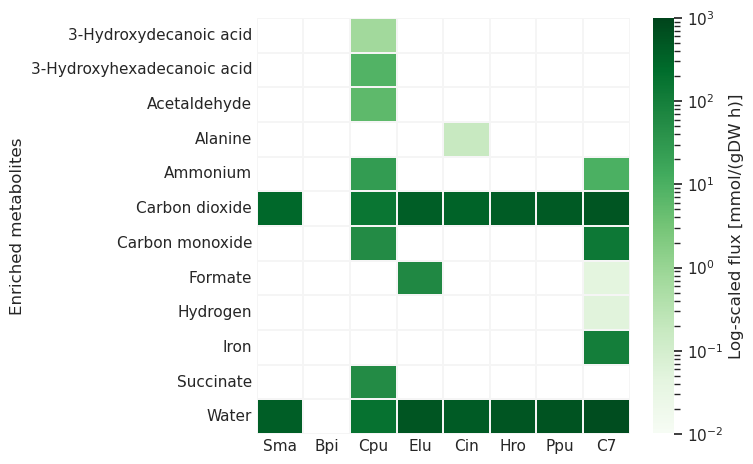

In [29]:
vmin = 0.01
width = 7.5
type = "secret"

#vmin = threshold: if all flux values for a metabolite are below, they dont show up in the plot to not screw the color scale too much
df_filtered = secret_df[secret_df.max(axis=1) >= vmin]

# Depending on Uptake or Secretion, choose different color scale
color_map = {"uptake": "Blues", "secret": "Greens"}
base_cmap_name = color_map[type]

# Build custom colormap that starts with white
base = sns.color_palette(base_cmap_name, 256).as_hex()
custom_colors = ["#ffffff"] + base[1:]  # replace first entry with white
custom_cmap = LinearSegmentedColormap.from_list(f"{base_cmap_name}_custom", custom_colors)

# Plot heatmap
plt.figure(figsize=(width, min(len(df_filtered) * 0.4, 32)))
plt.grid(False)

ax = sns.heatmap(
    df_filtered,
    cmap=custom_cmap,
    #norm=LogNorm(vmin=vmin, vmax=df_filtered.max().max()),
    norm=LogNorm(vmin=vmin, vmax=1000),
    cbar_kws={"label": "Log-scaled flux [mmol/(gDW h)]"},
    mask=df_filtered == 0,  # hide zero-flux cells
    linewidths=0.01,
    linecolor="whitesmoke"
)

# Clean up axes and background grid artifacts
ax.set_facecolor("white")  # fill background of masked cells with white
sns.despine(left=True, bottom=True)  # remove spines
ax.tick_params(length=0)  # remove tick marks

#plt.xlabel("Models")
plt.ylabel("Enriched metabolites")
plt.tight_layout()
#plt.savefig("../Figures/L_Secretion_Krumbach.svg", format="svg", bbox_inches="tight")
plt.show()

# Enrichment: Organoheterocyclic Compound

In [30]:
heterocyclic

,Organoheterocyclic_Compounds
Strain,
Sma,4
Bpi,2
Cpu,22
Elu,2
Cin,4
Hro,1
Ppu,3
C7,4


In [ ]:
sns.reset_defaults()

fig, ax = plt.subplots(figsize=(5.5,4))

# colour similar to heatmap palette
bar_color = "#339c52"  # medium green

ax.bar(
    heterocyclic.index,
    heterocyclic["Organoheterocyclic_Compounds"],
    color=bar_color
)

ax.set_ylabel("Number of enriched organoheterocyclic compounds")

ax.set_facecolor("white")  # fill background of masked cells with white
ax.grid(True, color="gainsboro", linewidth=0.8)

plt.tight_layout()
#plt.savefig("../Figures/K_Secretion_organoheterocyclic.svg", format="svg", bbox_inches="tight")
plt.show()

# Biolog Ecoplate

## Individuals Ecoplate

In [ ]:
# calculate mean
ecoplate_ind_mean_V = (
    ecoplate_ind_V.groupby(ecoplate_ind_V.columns.str.split('_r').str[0], axis=1)
    .mean()
)

In [ ]:
# make sure index and substrate column are comparable
ecoplate_ind_mean_V.index = ecoplate_ind_mean_V.index.astype(str).str.strip()
ecoplate_categories['Substrate'] = ecoplate_categories['Substrate'].astype(str).str.strip()


In [ ]:
# Rename and reorder columns
ecoplate_ind_mean_V = ecoplate_ind_mean_V.rename(
    columns={
        "Ecl": "Elu",
        "Hfr": "Hro",
        "Opi": "Bpi"
    }
)

ecoplate_ind_mean_V = ecoplate_ind_mean_V[order]

In [ ]:
# For K
ecoplate_ind_mean_V_trimmed = ecoplate_ind_mean_V.loc[ecoplate_ind_mean_V.index.isin(ecoplate_substrate_names['K'])]
ecoplate_ind_mean_V_trimmed = ecoplate_ind_mean_V_trimmed.reindex(ecoplate_substrate_names['K'])

# For L
ecoplate_ind_S_trimmed = ecoplate_ind_S.loc[ecoplate_ind_S.index.isin(ecoplate_substrate_names['L'])]
ecoplate_ind_S_trimmed = ecoplate_ind_S_trimmed.reindex(ecoplate_substrate_names['L'])

### Full length

In [ ]:
# change order of substrates according to chemical category
ecoplate_ind_mean_V = ecoplate_ind_mean_V.reindex(ecoplate_categories['Substrate'])

In [ ]:
ecoplate_ind_mean_V = ecoplate_ind_mean_V.fillna(0) # fill NaN with 0
# Krumbach excluded two metabolites from their analysis because they didnt see growth in any scenario, so we can just set the values to 0 instead of NaN

In [ ]:
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(4.5,8.5)})

ax = sns.heatmap(
    ecoplate_ind_mean_V,
    cmap="Reds",
    cbar_kws={"label": "A590 value"}
)

ax.set_xticklabels(ax.get_xticklabels())

# set colourbar ticks
cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 0.5, 1.0, 1.5, 2.0])

ax.set_ylabel("")


#plt.savefig(f"{path_to_figures}K_2a_Ecoplate-Ind_ALL.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
mapping = dict(zip(ecoplate_substrate_names['L'], ecoplate_substrate_names['K']))
ecoplate_ind_S = ecoplate_ind_S.rename(index=mapping)

In [ ]:
# change order of substrates according to chemical category; also adds all the substrates that are missing
ecoplate_ind_S = ecoplate_ind_S.reindex(ecoplate_categories['Substrate'])

In [ ]:
# plot
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(4.5,8.5)})

ax = sns.heatmap(
    ecoplate_ind_S,
    cmap="Reds",
    cbar_kws={"label": "Growth rate [mmol/(gDW h)]"}
)

ax.set_xticklabels(ax.get_xticklabels())

ax.grid(False)
ax.set_facecolor("gainsboro")

ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}L_2a_Ecoplate-Ind_All.svg", format="svg", bbox_inches="tight")
plt.show()

### Trimmed

In [ ]:
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(4.5,8)})

ax = sns.heatmap(
    ecoplate_ind_mean_V_trimmed,
    cmap="Reds",
    cbar_kws={"label": "A590 value"}
)

ax.set_xticklabels(ax.get_xticklabels())

# set colourbar ticks
cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 0.5, 1.0, 1.5, 2.0])

ax.set_ylabel("")


#plt.savefig(f"{path_to_figures}to_edit/???.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
# plot
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(4.5,8)})

ax = sns.heatmap(
    ecoplate_ind_S_trimmed,
    cmap="Reds",
    cbar_kws={"label": "Growth rate [mmol/(gDW h)]"}
)

ax.set_xticklabels(ax.get_xticklabels())

# set colourbar ticks
cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 0.5, 1.0, 1.5, 2.0, 2.5])

ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}to_edit/??.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
# rename L df so it has the same metabolite names as K
mapping = dict(zip(ecoplate_substrate_names['L'], ecoplate_substrate_names['K']))
ecoplate_ind_S_trimmed = ecoplate_ind_S_trimmed.rename(index=mapping)

In [ ]:
# plot
sns.set_style("darkgrid")
sns.set_theme(rc={'figure.figsize':(4.5,8)})

ax = sns.heatmap(
    ecoplate_ind_S_trimmed,
    cmap="Reds",
    cbar_kws={"label": "Growth rate [mmol/(gDW h)]"}
)

ax.set_xticklabels(ax.get_xticklabels())

# set colourbar ticks
cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 0.5, 1.0, 1.5, 2.0, 2.5])

ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}to_edit/??.svg", format="svg", bbox_inches="tight")
plt.show()

### Trimmed & Clustered

In [ ]:
# with clustering

sns.set_style("darkgrid")

g = sns.clustermap(
    ecoplate_ind_mean_V_trimmed,
    cmap="Reds",
    figsize=(7, 8),
    cbar_kws={"label": "A590"},
    metric="euclidean",
    method="average",
    standard_scale=0,   # None or 0 (rows) or 1 (columns) if you want scaling
    row_cluster=True,
    col_cluster=False
)

g.ax_heatmap.set_ylabel("")

# remove y axis tick marks but keep labels
g.ax_heatmap.tick_params(axis="y", length=0)

# Move colour bar to the right and make it full height
g.cax.set_position([0.97, 0.08, 0.05, 0.71]) # [x, y, width, height]

plt.savefig(f"{path_to_figures}to_edit/K_2a_Ecoplate-Ind_Clustering.svg", format="svg", bbox_inches="tight")
plt.show()

## C6 Ecoplate

### In vitro data

In [ ]:
base = plt.cm.Reds
colors = base(np.linspace(0, 0.88, 256))  # cut off darkest 25%
cmap_lightred = LinearSegmentedColormap.from_list("Reds_soft", colors)

In [ ]:
ecoplate_c6_V.columns = ecoplate_c6_V.columns.str.replace(" ", "", regex=False)
ecoplate_c6_mean_V = (
    ecoplate_c6_V.groupby(ecoplate_c6_V.columns.str.split('_r').str[0], axis=1)
    .mean()
)

In [ ]:
ecoplate_c6_mean_V = ecoplate_c6_mean_V.rename(
    columns={
        "C6–Ecl": "C6–Elu",
        "C6–Hfr": "C6–Hro",
        "C6–Opi": "C6–Bpi"
    }
)

ecoplate_c6_mean_V = ecoplate_c6_mean_V[order_c6]

In [ ]:
ecoplate_c6_mean_V = ecoplate_c6_mean_V.rename(
    columns={
        "C6–Elu": "C7–Elu",
        "C6–Hro": "C7–Hro",
        "C6–Bpi": "C7–Bpi",
        "C6–Sma": "C7–Sma",
        "C6–Cpu": "C7–Cpu",
        "C6–Cin": "C7–Cin",
        "C6–Ppu": "C7–Ppu"
    }
)


In [ ]:
ecoplate_c6_mean_V

In [ ]:
ecoplate_substrate_names_trim = ecoplate_substrate_names[:-1] # leave lactose out

In [ ]:
# For K
ecoplate_c6_mean_V_trimmed = ecoplate_c6_mean_V.loc[ecoplate_c6_mean_V.index.isin(ecoplate_substrate_names_trim['K'])]
ecoplate_c6_mean_V_trimmed = ecoplate_c6_mean_V_trimmed.reindex(ecoplate_substrate_names_trim['K'])

# For L
ecoplate_c6_S_trimmed = ecoplate_c6_S.loc[ecoplate_c6_S.index.isin(ecoplate_substrate_names_trim['L'])]
ecoplate_c6_S_trimmed = ecoplate_c6_S_trimmed.reindex(ecoplate_substrate_names_trim['L'])

In [ ]:
# change order of substrates according to chemical category
ecoplate_c6_mean_V = ecoplate_c6_mean_V.reindex(ecoplate_categories['Substrate'])

In [ ]:
ecoplate_c6_mean_V = ecoplate_c6_mean_V.fillna(0)

In [ ]:
# full length without clustering

sns.set_style("darkgrid")

g = sns.clustermap(
    ecoplate_c6_mean_V,
    cmap=cmap_lightred,
    figsize=(6, 9),
    cbar_kws={"label": "A590 value"},
    metric="euclidean",
    method="average",
    standard_scale=0,   # None or 0 (rows) or 1 (columns) if you want scaling
    # because we have rows that only contain 0, scaling is not possible :c
    row_cluster=False,
    col_cluster=False,
    dendrogram_ratio=(0.2, 0.1)   # row width, column height
)

g.ax_heatmap.set_ylabel("")

# remove y axis tick marks but keep labels
g.ax_heatmap.tick_params(axis="y", length=0)

# Move colour bar to the right and make it full height
g.cax.set_position([0.97, 0.12, 0.05, 0.78]) # [x, y, width, height]

plt.savefig(f"{path_to_figures}K_3a_Ecoplate-C6_ALL.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
# with clustering and trimmed (color adaption)

sns.set_style("darkgrid")

g = sns.clustermap(
    ecoplate_c6_mean_V_trimmed,
    cmap=cmap_lightred,
    figsize=(6, 8),
    cbar_kws={"label": "Scaled substrate utilisation"},
    metric="euclidean",
    method="average",
    standard_scale=0,   # None or 0 (rows) or 1 (columns) if you want scaling
    row_cluster=False,
    col_cluster=True,
    dendrogram_ratio=(0.2, 0.1)   # row width, column height
)

g.ax_heatmap.set_ylabel("")

# remove y axis tick marks but keep labels
g.ax_heatmap.tick_params(axis="y", length=0)

# Move colour bar to the right and make it full height
g.cax.set_position([0.97, 0.12, 0.05, 0.77]) # [x, y, width, height]

#plt.savefig(f"{path_to_figures}K_3a_Ecoplate-C6_trim.svg", format="svg", bbox_inches="tight")
plt.show()

### In silico data

In [ ]:
# sort df by row/index names
ecoplate_c6_S = ecoplate_c6_S.sort_index()

In [ ]:
mapping = dict(zip(ecoplate_substrate_names['L'], ecoplate_substrate_names['K']))
ecoplate_c6_S = ecoplate_c6_S.rename(index=mapping)
# change order of substrates according to chemical category; also adds all the substrates that are missing

In [ ]:
ecoplate_c6_S = ecoplate_c6_S.reindex(ecoplate_categories['Substrate'])
ecoplate_c6_S = ecoplate_c6_S.fillna(0) # otherwise the heatmap will not work at all

In [ ]:
# full without clustering (colour adapt)

sns.set_style("darkgrid")

g = sns.clustermap(
    ecoplate_c6_S,
    cmap=cmap_lightred,
    figsize=(6, 9),
    cbar_kws={"label": "Growth rate [mmol/(gDW h)]"},
    metric="euclidean",
    method="average",
    standard_scale=0,   # None or 0 (rows) or 1 (columns) if you want scaling
    row_cluster=False,
    col_cluster=False,
    dendrogram_ratio=(0.2, 0.1)   # row width, column height
)

g.ax_heatmap.set_ylabel("")

# remove y axis tick marks but keep labels
g.ax_heatmap.tick_params(axis="y", length=0)

# Move colour bar to the right and make it full height
g.cax.set_position([0.97, 0.12, 0.05, 0.78]) # [x, y, width, height]

plt.savefig(f"{path_to_figures}L_3a_Ecoplate-C6_ALL.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
# with clustering and trimmed and colour adapt

sns.set_style("darkgrid")

g = sns.clustermap(
    ecoplate_c6_S_trimmed,
    cmap=cmap_lightred,
    figsize=(6, 8),
    cbar_kws={"label": "Scaled growth rate"},
    metric="euclidean",
    method="average",
    standard_scale=0,   # None or 0 (rows) or 1 (columns) if you want scaling
    row_cluster=False,
    col_cluster=True,
    dendrogram_ratio=(0.2, 0.1)   # row width, column height
)

g.ax_heatmap.set_ylabel("")

# remove y axis tick marks but keep labels
g.ax_heatmap.tick_params(axis="y", length=0)

# Move colour bar to the right and make it full height
g.cax.set_position([0.97, 0.12, 0.05, 0.77]) # [x, y, width, height]

#plt.savefig(f"{path_to_figures}L_3a_Ecoplate-C6_trim-lighter.svg", format="svg", bbox_inches="tight")
#plt.savefig(f"{path_to_figures}L_3a_Ecoplate-C6_trim-lighter_NOrow.svg", format="svg", bbox_inches="tight")
plt.show()

# Carbon Source Utilisation

In [ ]:
plt.close("all")
cell_w = 0.6  # inches per column
cell_h = 0.45   # inches per row

In [ ]:
sns.set_style("darkgrid")
#sns.set_theme(rc={'figure.figsize': (4, 4)})

n_rows, n_cols = carbon_util_S.iloc[:, :-1].shape

fig_w = n_cols * cell_w
fig_h = n_rows * cell_h

fig, ax = plt.subplots(figsize=(fig_w, fig_h))


divider = make_axes_locatable(ax)
cbar_ax = divider.append_axes("right", size="10%", pad=0.2)

ax = sns.heatmap(
    carbon_util_S.iloc[:, :-1],
    cmap="Reds",
    ax=ax,
    cbar_ax=cbar_ax,
    cbar_kws={"label": "Growth rate [mmol/(gDW h)]"}
)

cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 0.5, 1, 1.5, 2])

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}L_4a_Carbon-util.svg", format="svg", bbox_inches="tight")
plt.show()


In [ ]:
carbon_util_V.columns = order[:-1]

In [ ]:
sns.set_style("darkgrid")

n_rows, n_cols = carbon_util_V.shape
fig_w = n_cols * cell_w
fig_h = n_rows * cell_h
fig, ax = plt.subplots(figsize=(fig_w, fig_h))


divider = make_axes_locatable(ax)
cbar_ax = divider.append_axes("right", size="10%", pad=0.2)

ax = sns.heatmap(
    carbon_util_V,
    cmap="Reds",
    ax=ax,
    cbar_ax=cbar_ax,
    cbar_kws={"label": "Bacterial growth"}
)

cbar = ax.collections[0].colorbar
cbar.set_ticks([0, 2, 4, 6, 8, 10])

ax.set_xticklabels(ax.get_xticklabels())
ax.set_ylabel("")

#plt.savefig(f"{path_to_figures}K_4a_Carbon-util.svg", format="svg", bbox_inches="tight")
plt.show()


In [ ]:
carbon_util_alanine_V["Strain"] = [strain for strain in order[:-1] for _ in range(3)]

In [ ]:
# exclude two outliers from further calculations
# Cin 1 and Hfr 2
# in pandas ~ is the negation operator (! is python syntax)
carbon_util_alanine_V = carbon_util_alanine_V[~((carbon_util_alanine_V["Strain"] == "Hfr") & (carbon_util_alanine_V["Rep"] == 2))]
carbon_util_alanine_V = carbon_util_alanine_V[~((carbon_util_alanine_V["Strain"] == "Cin") & (carbon_util_alanine_V["Rep"] == 1))]

In [ ]:
carbon_util_alanine_V_new = carbon_util_alanine_V.T
carbon_util_alanine_V_new.columns = carbon_util_alanine_V["Strain"]
carbon_util_alanine_V_new = carbon_util_alanine_V_new[2:]

In [ ]:
carbon_util_alanine_V_new.index = (
    carbon_util_alanine_V_new.index
      .astype(str)
      .str.replace(",", ".", regex=False)
      .astype(float)
)

In [ ]:
carbon_util_alanine_V_mean = (
    carbon_util_alanine_V_new.groupby(carbon_util_alanine_V_new.columns, axis=1).mean()
)

carbon_util_alanine_V_sd = (
    carbon_util_alanine_V_new.groupby(carbon_util_alanine_V_new.columns, axis=1).std()
)

carbon_util_alanine_V_mean = carbon_util_alanine_V_mean[order[:-1]]
carbon_util_alanine_V_sd = carbon_util_alanine_V_sd[order[:-1]]

In [ ]:
# convert index from seconds to hours
time_hours = carbon_util_alanine_V_mean.index / 3600

In [ ]:
plt.figure(figsize=(8, 5))

for strain in carbon_util_alanine_V_mean.columns:
    plt.plot(time_hours, carbon_util_alanine_V_mean[strain], label=strain)

plt.xlabel("Time (hours)")
plt.ylabel("Growth")
plt.title("Growth curves of bacterial strains")
plt.legend(title="Strain")
plt.tight_layout()
plt.show()


In [ ]:
# define custom colours
strain_colors = {
    "Sma": "#7B113A",       # wine red
    "Bpi": "#40E0D0",       # bright light blue
    "Cpu": "#FFD700",       # yellow
    "Elu": "#000bde",       # dark blue
    "Cin": "#289e96",       # turquoise
    "Hro": "#f7968b",       # salmon
    "Ppu": "#00bf1d"        # bright green
}

plt.figure(figsize=(8, 5))

# set axis background to white
ax = plt.gca()
ax.set_facecolor("white")

# customize grid / axes lines
ax.grid(True, color="lightgray", linestyle="-", linewidth=0.5)

for strain in carbon_util_alanine_V_mean.columns:
    mean = carbon_util_alanine_V_mean[strain]
    sd = carbon_util_alanine_V_sd[strain]

    color = strain_colors.get(strain, "black")  # default black if missing

    # plot mean line in custom color
    plt.plot(time_hours, mean, label=strain, color=color, linewidth=2)

    # plot SD band in the same color with transparency
    plt.fill_between(
        time_hours,
        mean - sd,
        mean + sd,
        color=color,
        alpha=0.2
    )

plt.xlabel("Time (h)")
plt.ylabel("OD600")
#plt.title("Fig. 4b: Growth curves of all seven strains with alanine as sole carbon source")
plt.legend(title="Strain")
plt.tight_layout()
#plt.savefig(f"{path_to_figures}K_4b_Growth_Curves_Alanine.svg", format="svg", bbox_inches="tight")
plt.show()


# Cross-Feeding

## In silico: heatmap

In [ ]:
#donors = ["Fresh", "Elu", "Cin", "Hro", "Ppu"] # drop Cin to match in vitro data
donors = ["Fresh", "Elu", "Hro", "Ppu"] 
possible_carbons = [["EX_glc__D_e"], ["EX_mal__L_e"], ["EX_ala__L_e"]]

In [ ]:
cross_feeding_S_wo_Cin = cross_feeding_S.drop(["Glucose_Cin", "Malate_Cin", "Alanine_Cin"], inplace=False, axis=0)

In [ ]:
sns.reset_defaults()

In [ ]:
n_rows, n_cols = cross_feeding_S_wo_Cin.shape
fig_w = n_cols * cell_w
fig_h = n_rows * cell_h
fig, ax = plt.subplots(figsize=(fig_w, fig_h))

#plt.figure(figsize=(fig_w, fig_h))

#cross_feed_numeric = cross_feed_df.apply(pd.to_numeric, errors='coerce')
#annot_str = cross_feed_numeric.applymap(custom_format)


annot_str = cross_feeding_S_wo_Cin.applymap(custom_format)
ax = sns.heatmap(
    cross_feeding_S_wo_Cin, cmap="Reds", fmt="", linewidths=0.0, linecolor="none", square=False, annot=False # annot_str or False
)

# Access and move colorbar
cbar = ax.collections[0].colorbar
cbar.ax.set_position([0.98, 0.0, 0.05, 1])  # [x, y, width, height]
cbar.ax.set_ylabel("Growth rate [mmol/(gDW h)]", fontsize=10)

ax.set_ylabel("Carbon source for donor strain growth", labelpad=30, fontsize=12)
group_names = ["Glucose", "Malate", "Alanine"]
group_size = len(donors)  # how many rows per group

# Remove the left y tick labels (to avoid repetition)
ax.set_yticklabels([])

# Add group labels manually
for i, group in enumerate(group_names):
    # y position: middle of each block
    y_pos = (i * group_size) + group_size / 2
    ax.text(
        -0.17, y_pos, group, va="center", ha="right", rotation=90,
        fontsize=10, transform=ax.transData)

# Right y-axis labels
ax_right = ax.twinx()
ax_right.set_ylim(ax.get_ylim())
ax_right.set_ylabel("Medium for recipient", fontsize=12, labelpad=15)

right_labels = donors * 3
ax_right.set_yticks(np.arange(len(right_labels)) + 0.5)
ax_right.set_yticklabels(right_labels, rotation=0, fontsize=10)


for i in range(len(donors), len(donors)*len(possible_carbons)+1, len(donors)):  # add horizontal lines
    plt.hlines(i, *plt.xlim(), color='black', linewidth=1)

custom_x_labels = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]
ax.set_xticklabels(custom_x_labels, fontsize=10)
ax.set_xlabel("Recipient strain", fontsize=12)

# Remove automatic ticks/grid
ax.tick_params(axis='y', which='both', left=False)
ax.tick_params(axis='x', which='both', bottom=False)
ax.set_facecolor("none")
ax.grid(False)

# remove spines (black border)
for spine in ax.spines.values():
    spine.set_visible(False)
for spine in ax_right.spines.values():
    spine.set_visible(False)


#plt.title("Cross-feeding")
#plt.savefig(f"{path_to_figures}L_4c_Cross-Feeding.svg", format="svg", bbox_inches="tight")
plt.show()

## In vitro: heatmap

In [ ]:
donors = ["Fresh", "Elu", "Hro", "Ppu"]
possible_carbons = [["EX_glc__D_e"], ["EX_mal__L_e"], ["EX_ala__L_e"]]

In [ ]:
cross_feeding_V.index = cross_feeding_V["Carbon source"]+"_"+cross_feeding_V["Medium history"]
cross_feeding_V.drop(columns=["Carbon source", "Medium history"], inplace=True)

In [ ]:
n_rows, n_cols = cross_feeding_V.shape
fig_w = n_cols * cell_w
fig_h = n_rows * cell_h
#fig, ax = plt.subplots(figsize=(fig_w, fig_h))

plt.figure(figsize=(fig_w, fig_h))

#cross_feed_numeric = cross_feed_df.apply(pd.to_numeric, errors='coerce')
#annot_str = cross_feed_numeric.applymap(custom_format)


annot_str = cross_feeding_V.applymap(custom_format)
ax = sns.heatmap(
    cross_feeding_V, cmap="Reds", fmt="", linewidths=0.0, linecolor="none", square=False, annot=False # False or annot_str
)

# Access and move colorbar
cbar = ax.collections[0].colorbar
cbar.ax.set_position([0.98, 0.0, 0.05, 1])  # [x, y, width, height]
cbar.ax.set_ylabel("Bacterial growth", fontsize=10)

ax.set_ylabel("Carbon source for donor strain growth", labelpad=30, fontsize=12)
group_names = ["Glucose", "Malate", "Alanine"]
group_size = len(donors)  # how many rows per group

# Remove the left y tick labels (to avoid repetition)
ax.set_yticklabels([])

# Add group labels manually
for i, group in enumerate(group_names):
    # y position: middle of each block
    y_pos = (i * group_size) + group_size / 2
    ax.text(
        -0.17, y_pos, group, va="center", ha="right", rotation=90,
        fontsize=10, transform=ax.transData)

# Right y-axis labels
ax_right = ax.twinx()
ax_right.set_ylim(ax.get_ylim())
ax_right.set_ylabel("Medium for recipient", fontsize=12, labelpad=15)

right_labels = donors * 3
ax_right.set_yticks(np.arange(len(right_labels)) + 0.5)
ax_right.set_yticklabels(right_labels, rotation=0, fontsize=10)


for i in range(len(donors), len(donors)*len(possible_carbons)+1, len(donors)):  # add horizontal lines
    plt.hlines(i, *plt.xlim(), color='black', linewidth=1)

custom_x_labels = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]
ax.set_xticklabels(custom_x_labels, fontsize=10)
ax.set_xlabel("Recipient strain", fontsize=12)

# Remove automatic ticks/grid
ax.tick_params(axis='y', which='both', left=False)
ax.tick_params(axis='x', which='both', bottom=False)
ax.set_facecolor("none")
ax.grid(False)


# remove spines (black border)
for spine in ax.spines.values():
    spine.set_visible(False)
for spine in ax_right.spines.values():
    spine.set_visible(False)


#plt.title("Cross-feeding")
#plt.savefig(f"{path_to_figures}K_4c_Cross-Feeding.svg", format="svg", bbox_inches="tight")
plt.show()

## In vitro: Bpi growth curve

In [ ]:
cross_feeding_bpi_V.index = cross_feeding_bpi_V["Medium history"]
cross_feeding_bpi_new_V = cross_feeding_bpi_V.drop(columns=["Strain", "Medium history", "Rep", "File_name", "Well"], inplace=False)

In [ ]:
cross_feeding_bpi_new_V = cross_feeding_bpi_new_V.T

In [ ]:
cross_feeding_bpi_new_V.index = (
    cross_feeding_bpi_new_V.index
      .astype(str)
      .str.replace(",", ".", regex=False)
      .astype(float)
)

In [ ]:
name_map = {"Ecl": "Elu",
            "Hfr": "Hro"}

cross_feeding_bpi_new_V = cross_feeding_bpi_new_V.rename(columns=name_map)

In [ ]:
cross_feeding_bpi_V_mean = (
    cross_feeding_bpi_new_V.groupby(cross_feeding_bpi_new_V.columns, axis=1).mean()
)

cross_feeding_bpi_V_sd = (
    cross_feeding_bpi_new_V.groupby(cross_feeding_bpi_new_V.columns, axis=1).std()
)

order_cross_bpi = ["Fresh", "Elu", "Hro", "Ppu"]
cross_feeding_bpi_V_mean = cross_feeding_bpi_V_mean[order_cross_bpi]
cross_feeding_bpi_V_sd = cross_feeding_bpi_V_sd[order_cross_bpi]

In [ ]:
# convert index from seconds to hours
time_hours = cross_feeding_bpi_V_mean.index / 3600

In [ ]:
plt.figure(figsize=(8, 5))

for strain in cross_feeding_bpi_V_mean.columns:
    plt.plot(time_hours, cross_feeding_bpi_V_mean[strain], label=strain)

plt.xlabel("Time (hours)")
plt.ylabel("Growth")
plt.title("Growth curves of bacterial strains")
plt.legend(title="Strain")
plt.tight_layout()
plt.show()

In [ ]:
# define custom colours
strain_colors = {
    "Fresh": "#40E0D0",       # bright light blue
    "Elu": "#000bde",       # dark blue
    "Hro": "#f7968b",       # salmon
    "Ppu": "#00bf1d"        # bright green
}

plt.figure(figsize=(8, 5))

# set axis background to white
ax = plt.gca()
ax.set_facecolor("white")

# remove spines
for spine in ax.spines.values():
    spine.set_visible(False)

# grid
ax.grid(True, color="lightgray", linestyle="-", linewidth=0.5)

# ticks and tick labels styled like the grid
ax.tick_params(
    axis="both",
    which="both",
    color="lightgray",      # tick lines
    labelcolor="black", # tick labels
    length=4,
    width=0.5
)


for strain in cross_feeding_bpi_V_mean.columns:
    mean = cross_feeding_bpi_V_mean[strain]
    sd = cross_feeding_bpi_V_sd[strain]

    color = strain_colors.get(strain, "black")  # default black if missing

    # plot mean line in custom color
    plt.plot(time_hours, mean, label=strain, color=color, linewidth=2)

    # plot SD band in the same color with transparency
    plt.fill_between(
        time_hours,
        mean - sd,
        mean + sd,
        color=color,
        alpha=0.2
    )

plt.xlabel("Time (h)")
plt.ylabel("OD600")
#plt.title("Fig. 4d: Growth curve of Bpi in different cross-feeding scenarios")
plt.legend(title="Medium history")


plt.tight_layout()
#plt.savefig(f"{path_to_figures}K_4d_Cross-Feeding_Bpi.svg", format="svg", bbox_inches="tight")
plt.show()

# Vitamin Response

## Bar chart for all strains (V0, V8)

In [ ]:
plt.close("all")

In [ ]:
name_map = {"Opi":"Bpi",
            "Ecl":"Elu",
            "Hfr": "Hro"}
vitamin_V["Strain"] = vitamin_V["Strain"].replace(name_map)

In [ ]:
strain_order = ["Sma", "Bpi", "Cpu", "Elu", "Cin", "Hro", "Ppu"]
vitamin_order = ["V0", "V8"]

vitamin_V_plot = (
    vitamin_V
    .assign(
        Strain=pd.Categorical(vitamin_V["Strain"], categories=strain_order, ordered=True),
        Vitamins=pd.Categorical(vitamin_V["Vitamins"], categories=vitamin_order, ordered=True)
    )
    .sort_values(["Strain", "Vitamins"])
)


In [ ]:
legend_labels = {
    "V0": "V0 (No vitamins)",
    "V8": "V8 (Full B-vitamin mix)"
}

In [ ]:
# colour palette
palette = {
    "V0": "#fcfbb1", # pale yellow
    "V8": "#7aa6d8" # pale blue
}

#strain_order = list(vitamin_V_plot["Strain"].unique())
#vitamin_order = ["V0", "V8"]

x = np.arange(len(strain_order))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(9, 5))

# plot bars
for i, vitamin in enumerate(vitamin_order):
    subset = vitamin_V_plot[vitamin_V_plot["Vitamins"] == vitamin]

    ax.bar(
        x + (i - 0.5) * bar_width,
        subset["Average_AUC"],
        width=bar_width,
        color=palette[vitamin],
        label=legend_labels[vitamin]
    )

# error bars
for _, row in vitamin_V.iterrows():
    strain_idx = strain_order.index(row["Strain"])
    vitamin_idx = vitamin_order.index(row["Vitamins"])

    x_pos = strain_idx + (vitamin_idx - 0.5) * bar_width

    ax.errorbar(
        x=x_pos,
        y=row["Average_AUC"],
        yerr=row["StD_AUC"],
        fmt="none",
        ecolor="black",
        capsize=4,
        linewidth=1.2
    )

# axis labels and ticks
ax.set_ylabel("Bacterial growth - AUC [OD600.h]", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(strain_order)
ax.set_xlabel("")

# legend
ax.legend(title="Vitamins", frameon=True, loc="center left", bbox_to_anchor=(1, 0.5))

# grid styling
ax.set_axisbelow(True)
ax.yaxis.grid(True, color="lightgray", linewidth=0.8)
ax.xaxis.grid(False)

# remove top and right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# set y-axis tick color to light gray
ax.tick_params(axis='y', colors='white', labelcolor='black')

# remove the left spine (y-axis line)
ax.spines['left'].set_visible(False)


plt.tight_layout()
#plt.savefig(f"{path_to_figures}K_5a_Vitamins_V0-V8.svg", format="svg", bbox_inches="tight")
plt.show()


In [ ]:
legend_labels = {
    "V0": "V0 (No vitamins)",
    "V8": "V8 (Full B-vitamin mix)"
}

# colour palette
palette = {
    "V0": "#fcfbb1",  # pale yellow
    "V8": "#7aa6d8"   # pale blue
}

# x-axis labels
model_order = vitamin_S.index.tolist()  # use index as x labels
x = np.arange(len(model_order))
bar_width = 0.4

fig, ax = plt.subplots(figsize=(9, 5))

# plot V0 bars
ax.bar(
    x - bar_width/2,
    vitamin_S["growth_V0"],
    width=bar_width,
    color=palette["V0"],
    label=legend_labels["V0"]
)

# plot V8 bars
ax.bar(
    x + bar_width/2,
    vitamin_S["growth_V8"],
    width=bar_width,
    color=palette["V8"],
    label=legend_labels["V8"]
)
ax.set_ylim(0, 16)

# axis labels and ticks
ax.set_ylabel("Growth rate [mmol/(gDW h)]]", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=45, ha="right")
#ax.set_xlabel("Model")

# legend
ax.legend(title="Vitamins", frameon=True, loc="center left", bbox_to_anchor=(1, 0.5))

# grid styling
ax.set_axisbelow(True)
ax.yaxis.grid(True, color="lightgray", linewidth=0.8)
ax.xaxis.grid(False)

# remove top and right spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# set y-axis tick color and remove left spine
ax.tick_params(axis='y', colors='white', labelcolor='black')
ax.spines['left'].set_visible(False)

plt.tight_layout()
#plt.savefig(f"{path_to_figures}L_5a_Vitamins_V0-V8.svg", format="svg", bbox_inches="tight")
plt.show()


## Growth Curves V0 & V8 (Bpi, Elu)

In [ ]:
name_map = {"Opi":"Bpi",
            "Ecl":"Elu"}
vitamin_bpi_elu_V["Strain"] = vitamin_bpi_elu_V["Strain"].replace(name_map)

In [ ]:
vitamin_bpi_elu_V.index = vitamin_bpi_elu_V["Strain"]+"_"+vitamin_bpi_elu_V["Vitamin_addition"]
vitamin_bpi_elu_new_V = vitamin_bpi_elu_V.drop(columns=["Strain", "Vitamin_addition", "Rep", "Well"],
                                                   inplace=False)

In [ ]:
vitamin_bpi_elu_new_V = vitamin_bpi_elu_new_V.T

In [ ]:
vitamin_bpi_elu_new_V.index = (
    vitamin_bpi_elu_new_V.index
    .astype(str)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

In [ ]:
vitamin_bpi_elu_new_V_mean = (
    vitamin_bpi_elu_new_V.groupby(vitamin_bpi_elu_new_V.columns, axis=1).mean()
)

vitamin_bpi_elu_new_V_sd = (
    vitamin_bpi_elu_new_V.groupby(vitamin_bpi_elu_new_V.columns, axis=1).std()
)

In [ ]:
# convert index from seconds to hours
time_hours = cross_feeding_bpi_V_mean.index / 3600

In [ ]:
# define custom colours
strain_colors = {
    "Bpi_V0": "#40E0D0",       # bright light blue
    "Elu_V0": "#000bde",       # dark blue
    "Bpi_V8": "#e010a2",       # dark pink
    "Elu_V8": "#dfb7eb"        # light purple
}

plt.figure(figsize=(8, 5))

# set axis background to white
ax = plt.gca()
ax.set_facecolor("white")

# remove spines
for spine in ax.spines.values():
    spine.set_visible(False)

# grid
ax.grid(True, color="lightgray", linestyle="-", linewidth=0.5)

# ticks and tick labels styled like the grid
ax.tick_params(
    axis="both",
    which="both",
    color="lightgray",      # tick lines
    labelcolor="black", # tick labels
    length=4,
    width=0.5
)

legend_labels = {
    "Bpi_V0": "Bpi - V0 (no vitamins)",
    "Elu_V0": "Elu - V0 (no vitamins)",
    "Bpi_V8": "Bpi - V8 (Full B-vitamin mix)",
    "Elu_V8": "Elu - V8 (Full B-vitamin mix)"
}

for strain in vitamin_bpi_elu_new_V_mean.columns:
    mean = vitamin_bpi_elu_new_V_mean[strain]
    sd = vitamin_bpi_elu_new_V_sd[strain]

    color = strain_colors.get(strain, "black")  # default black if missing

    # plot mean line in custom color
    plt.plot(time_hours, mean, label=legend_labels.get(strain, strain), color=color, linewidth=2, )

    # plot SD band in the same color with transparency
    plt.fill_between(
        time_hours,
        mean - sd,
        mean + sd,
        color=color,
        alpha=0.2
    )

plt.xlabel("Time (h)")
plt.ylabel("OD600")
#plt.title("Fig. 5b: Growth curves of Bpi & Elu in different vitamin scenarios")
plt.legend(
    title="Strains & Vitamins",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  # x, y relative to axes
    frameon=False
)


plt.tight_layout()
#plt.savefig(f"{path_to_figures}K_5b_Vitamin_Bpi-Elu.svg", format="svg", bbox_inches="tight")
plt.show()

## Bar chart V1 (Bpi)

In [ ]:
vitamin_V1_bpi_new_V = vitamin_V1_bpi_V.copy()

In [ ]:
vitamin_V1_bpi_new_V.index = vitamin_V1_bpi_V["Vitamins"]
vitamin_V1_bpi_new_V = vitamin_V1_bpi_new_V.drop(columns=["Strain", "Substrate","Vitamins"], inplace=False)
vitamin_V1_bpi_new_V = vitamin_V1_bpi_new_V.T

In [ ]:
vitamin_V1_bpi_V_mean = (
    vitamin_V1_bpi_new_V.mean()
)

vitamin_V1_bpi_V_sd = (
    vitamin_V1_bpi_new_V.std()
)

In [ ]:
# Convert single-column DataFrames to Series
mean_vals = vitamin_V1_bpi_V_mean.squeeze()
sd_vals = vitamin_V1_bpi_V_sd.squeeze()

x = range(len(mean_vals))

plt.figure(figsize=(8, 5))


plt.bar(
    x,
    mean_vals,
    yerr=sd_vals,
    color='#fcfbb1',  # pale yellow
    capsize=5,
    zorder=3 # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
)

plt.xticks(x, vitamin_V1_bpi_V_mean.index, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Bacterial growth of Bpi - AUC [OD600.h]", fontsize=12)


# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}K_6a_Vitamins_Bpi_V1.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
xlabels = [
    label if label.startswith("V") else "+ " + label
    for label in vitamin_V1_V7_bpi_S.index
]

In [ ]:
plt.figure(figsize=(8, 5))

x = range(len(vitamin_V1_V7_bpi_S))

plt.bar(x,
    vitamin_V1_V7_bpi_S["V1"],
    color='#fcfbb1',  # pale yellow
    capsize=5,
    zorder=3 # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
)

plt.xticks(x, xlabels, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Growth rate of Bpi [mmol/(gDW h)]", fontsize=12)


# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}L_6a_Vitamins_Bpi_V1.svg", format="svg", bbox_inches="tight")
plt.show()

## Bar chart V7 (Bpi)

In [ ]:
vitamin_V7_bpi_new_V = vitamin_V7_bpi_V.copy()

In [ ]:
vitamin_V7_bpi_new_V.index = vitamin_V7_bpi_V["Vitamins"]
vitamin_V7_bpi_new_V = vitamin_V7_bpi_new_V.drop(columns=["Strain", "Substrate", "Vitamins"], inplace=False)
vitamin_V7_bpi_new_V = vitamin_V7_bpi_new_V.T

In [ ]:
vitamin_V7_bpi_V_mean = (
    vitamin_V7_bpi_new_V.mean()
)

vitamin_V7_bpi_V_sd = (
    vitamin_V7_bpi_new_V.std()
)

In [ ]:
# Convert single-column DataFrames to Series
mean_vals = vitamin_V7_bpi_V_mean.squeeze()
sd_vals = vitamin_V7_bpi_V_sd.squeeze()

x = range(len(mean_vals))

plt.figure(figsize=(8, 5))

plt.bar(
    x,
    mean_vals,
    yerr=sd_vals,
    color='#7aa6d8',  # pale blue
    capsize=5,
    zorder=3  # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
)

plt.xticks(x, vitamin_V7_bpi_V_mean.index, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Bacterial growth of Bpi - AUC [OD600.h]", fontsize=12)
plt.ylim(0, 5)

# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}K_6b_Vitamins_Bpi_V7.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
xlabels = [
    label if label.startswith("V") else "- " + label
    for label in vitamin_V1_V7_bpi_S.index
]

In [ ]:
plt.figure(figsize=(8, 5))

x = range(len(vitamin_V1_V7_bpi_S))

plt.bar(x,
        vitamin_V1_V7_bpi_S["V7"],
        color='#7aa6d8',  # pale blue
        capsize=5,
        zorder=3  # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
        )

plt.xticks(x, xlabels, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Growth rate of Bpi [mmol/(gDW h)]", fontsize=12)

# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}L_6b_Vitamins_Bpi_V7.svg", format="svg", bbox_inches="tight")
plt.show()

## Growth curves V0, V2 & V8 (Bpi)

In [ ]:
vitamin_growth_bpi_V.index = vitamin_growth_bpi_V["Vitamin Status"].str.split(" ").str[0]

In [ ]:
vitamin_growth_bpi_new_V = vitamin_growth_bpi_V.drop(columns=["Strain", "Carbon Source", "Rep", "Data File", "Well", "Vitamin Status"])
vitamin_growth_bpi_new_V = vitamin_growth_bpi_new_V.T

In [ ]:
vitamin_growth_bpi_new_V.index = (
    vitamin_growth_bpi_new_V.index
    .astype(str)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

In [ ]:
vitamin_growth_bpi_new_V_mean = (
    vitamin_growth_bpi_new_V.groupby(vitamin_growth_bpi_new_V.columns, axis=1).mean()
)

vitamin_growth_bpi_new_V_sd = (
    vitamin_growth_bpi_new_V.groupby(vitamin_growth_bpi_new_V.columns, axis=1).std()
)

In [ ]:
# convert index from seconds to hours
time_hours = vitamin_growth_bpi_new_V_mean.index / 3600

In [ ]:
# define custom colours
strain_colors = {
    "V0": "#a3d95d",       # light pastel green
    "V2": "#d4282e",       # red
    "V8": "#31529e"       # dark blue
}

plt.figure(figsize=(8, 5))

# set axis background to white
ax = plt.gca()
ax.set_facecolor("white")

# remove spines
for spine in ax.spines.values():
    spine.set_visible(False)

# grid
ax.grid(True, color="lightgray", linestyle="-", linewidth=0.5)

# ticks and tick labels styled like the grid
ax.tick_params(
    axis="both",
    which="both",
    color="lightgray",      # tick lines
    labelcolor="black", # tick labels
    length=4,
    width=0.5
)

legend_labels = {
    "V0": "V0 (no vitamins)",
    "V2": "V2 (Thiamine & Biotin)",
    "V8": "V8 (Full B-vitamin mix)"
}

for strain in vitamin_growth_bpi_new_V_mean.columns:
    mean = vitamin_growth_bpi_new_V_mean[strain]
    sd = vitamin_growth_bpi_new_V_sd[strain]

    color = strain_colors.get(strain, "black")  # default black if missing

    # plot mean line in custom color
    plt.plot(time_hours, mean, label=legend_labels.get(strain, strain), color=color, linewidth=2, )

    # plot SD band in the same color with transparency
    plt.fill_between(
        time_hours,
        mean - sd,
        mean + sd,
        color=color,
        alpha=0.2
    )

plt.xlabel("Time (h)")
plt.ylabel("OD600")
#plt.title("Fig. 6c: Growth curves of Bpi in different vitamin scenarios")
plt.legend(
    title="Vitamins",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  # x, y relative to axes
    frameon=False
)


plt.tight_layout()
#plt.savefig(f"{path_to_figures}K_6c_Vitamin_Bpi_V0-2-8.svg", format="svg", bbox_inches="tight")
plt.show()

## Bar chart V1 (Cpu)

In [ ]:
vitamin_V1_cpu_new_V = vitamin_V1_cpu_V.copy()

In [ ]:
vitamin_V1_cpu_new_V.index = vitamin_V1_cpu_V["Vitamins"]
vitamin_V1_cpu_new_V = vitamin_V1_cpu_new_V.drop(columns=["Strain", "Substrate", "Vitamins"], inplace=False)
vitamin_V1_cpu_new_V = vitamin_V1_cpu_new_V.T

vitamin_V1_cpu_V_mean = (
    vitamin_V1_cpu_new_V.mean()
)

vitamin_V1_cpu_V_sd = (
    vitamin_V1_cpu_new_V.std()
)

In [ ]:
# Convert single-column DataFrames to Series
mean_vals = vitamin_V1_cpu_V_mean.squeeze()
sd_vals = vitamin_V1_cpu_V_sd.squeeze()

x = range(len(mean_vals))

plt.figure(figsize=(8, 5))


plt.bar(
    x,
    mean_vals,
    yerr=sd_vals,
    color='#fcfbb1',  # pale yellow
    capsize=5,
    zorder=3 # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
)

plt.xticks(x, vitamin_V1_cpu_V_mean.index, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Bacterial growth of Cpu - AUC [OD600.h]", fontsize=12)


# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}K_S3a_Vitamins_Cpu_V1.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
xlabels = [
    label if label.startswith("V") else "+ " + label
    for label in vitamin_V1_V7_cpu_S.index
]

In [ ]:
plt.figure(figsize=(8, 5))

x = range(len(vitamin_V1_V7_cpu_S))

plt.bar(x,
        vitamin_V1_V7_cpu_S["V1"],
        color='#fcfbb1',  # pale yellow
        capsize=5,
        zorder=3  # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
        )

plt.xticks(x, xlabels, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Growth rate of Cpu [mmol/(gDW h)]", fontsize=12)

# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}L_S3a_Vitamins_Cpu_V1.svg", format="svg", bbox_inches="tight")

plt.show()

## Bar chart V7 (Cpu)

In [ ]:
vitamin_V7_cpu_new_V = vitamin_V7_cpu_V.copy()

In [ ]:
vitamin_V7_cpu_new_V.index = vitamin_V7_cpu_V["Vitamins"]
vitamin_V7_cpu_new_V = vitamin_V7_cpu_new_V.drop(columns=["Strain", "Substrate", "Vitamins"], inplace=False)
vitamin_V7_cpu_new_V = vitamin_V7_cpu_new_V.T

vitamin_V7_cpu_V_mean = (
    vitamin_V7_cpu_new_V.mean()
)

vitamin_V7_cpu_V_sd = (
    vitamin_V7_cpu_new_V.std()
)

In [ ]:
# Convert single-column DataFrames to Series
mean_vals = vitamin_V7_cpu_V_mean.squeeze()
sd_vals = vitamin_V7_cpu_V_sd.squeeze()

x = range(len(mean_vals))

plt.figure(figsize=(8, 5))

plt.bar(
    x,
    mean_vals,
    yerr=sd_vals,
    color='#7aa6d8',  # pale blue
    capsize=5,
    zorder=3  # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
)

plt.xticks(x, vitamin_V7_cpu_V_mean.index, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Bacterial growth of Cpu - AUC [OD600.h]", fontsize=12)

# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}K_S3b_Vitamins_Cpu_V7.svg", format="svg", bbox_inches="tight")
plt.show()

In [ ]:
xlabels = [
    label if label.startswith("V") else "- " + label
    for label in vitamin_V1_V7_cpu_S.index
]

In [ ]:
plt.figure(figsize=(8, 5))

x = range(len(vitamin_V1_V7_cpu_S))

plt.bar(x,
        vitamin_V1_V7_cpu_S["V7"],
        color='#7aa6d8',  # pale blue
        capsize=5,
        zorder=3  # this needs to be a bit bigger than the zorder of the grid, so the grid lines are behind the bar
        )

plt.xticks(x, xlabels, rotation=45, ha='right')  # rotate if labels are long
plt.ylabel("Growth rate of Cpu [mmol/(gDW h)]", fontsize=12)

# Remove left y-axis spine
plt.gca().spines['left'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Add horizontal grid in light gray
plt.grid(axis='y', color='lightgray', linestyle='-', linewidth=0.8, zorder=0)

# Remove x-axis ticks but keep y-axis ticks
plt.tick_params(axis='y', length=0, colors='black')  # length=0 hides ticks, colors keeps labels
#plt.savefig(f"{path_to_figures}L_S3b_Vitamins_Cpu_V7.svg", format="svg", bbox_inches="tight")

plt.show()